# Tarea 3 — PyTorch

**Nombre del integrante:** Verónica Girón

**Cédula del integrante:** 29908725

> Enunciado, rúbrica y nombres de los archivos `.pth` a entregar: ver `README.md` de esta carpeta.
> Antes del commit: *Restart & Run All* debe terminar sin errores y quedar en el menú.

## 1. Imports y constantes

In [1]:
# imports and constants go here
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

NOTEBOOK_NUMBER = 2
DATA_DIR = "./data"          # gitignored
INPUT_SIZE = 28 * 28         # 784 input neurons, one per pixel
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Native Fashion MNIST order (label 0 .. 9)
ORIGINAL_CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Output order required by the .pth contract
SIMPLIFIED_CLASSES = ["Top", "Bottom", "Footwear", "Bag"]

# SIMPLIFIED_MAP[original_label] -> simplified label
SIMPLIFIED_MAP = [0, 1, 0, 1, 0, 2, 0, 2, 3, 2]

CLASS_NAMES = {"original": ORIGINAL_CLASSES, "simplified": SIMPLIFIED_CLASSES}

DEFAULT_OPTIONS = {
    "optimizer": "adam",       # "adam" or "sgd" (SGD uses momentum 0.9)
    "learning_rate": 0.001,
    "batch_size": 64,
    "dropout": 0.0,            # 0 = disabled
    "batch_norm": False,
    "weight_decay": 0.0,       # 0 = disabled (L2 regularization)
    "early_stopping": False,
    "patience": 3,             # epochs without validation improvement before stopping
}

torch.manual_seed(SEED)
np.random.seed(SEED)
print(f"PyTorch {torch.__version__} - device: {DEVICE}")

PyTorch 2.15.0+cpu - device: cpu


## 2. Datos (Fashion MNIST original y clases simplificadas)

In [2]:
# data loading goes here (download into ./data, which is gitignored)
def to_simplified(label):
    """Map an original Fashion MNIST label (0-9) to its simplified class (0-3)."""
    return SIMPLIFIED_MAP[label]


_dataset_cache = {}


def load_datasets(classification):
    """Return (train_data, test_data) for 'original' or 'simplified'."""
    if classification not in _dataset_cache:
        target_transform = to_simplified if classification == "simplified" else None
        common = dict(root=DATA_DIR, download=True,
                      transform=transforms.ToTensor(), target_transform=target_transform)
        train_data = datasets.FashionMNIST(train=True, **common)
        test_data = datasets.FashionMNIST(train=False, **common)
        _dataset_cache[classification] = (train_data, test_data)
    return _dataset_cache[classification]


def count_per_class(dataset, classification):
    """Count samples per class without iterating over the images."""
    labels = dataset.targets.numpy()
    if classification == "simplified":
        labels = np.array(SIMPLIFIED_MAP)[labels]
    return np.bincount(labels, minlength=len(CLASS_NAMES[classification]))


# Quick sanity check of both versions of the data
for kind in ("original", "simplified"):
    train_data, test_data = load_datasets(kind)
    image, label = train_data[0]
    print(f"[{kind}] train={len(train_data)} test={len(test_data)} "
          f"image shape={tuple(image.shape)} range=[{image.min():.1f}, {image.max():.1f}]")
    print("   train samples per class:",
          dict(zip(CLASS_NAMES[kind], count_per_class(train_data, kind).tolist())))

[original] train=60000 test=10000 image shape=(1, 28, 28) range=[0.0, 1.0]
   train samples per class: {'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000}
[simplified] train=60000 test=10000 image shape=(1, 28, 28) range=[0.0, 1.0]
   train samples per class: {'Top': 24000, 'Bottom': 12000, 'Footwear': 18000, 'Bag': 6000}


## 3. Modelos (rectangular y convolucional)

In [3]:
# model definitions go here
def compute_hidden_sizes(architecture, hidden_layers, neurons, num_classes):
    """Neurons per hidden layer for a rectangular or 'convolutional' (funnel) network."""
    if architecture == "rectangular":
        return [neurons] * hidden_layers
    # Linear interpolation between the input layer and the output layer
    step = (num_classes - INPUT_SIZE) / (hidden_layers + 1)
    return [round(INPUT_SIZE + step * i) for i in range(1, hidden_layers + 1)]


def build_model(hidden_sizes, num_classes, dropout=0.0, batch_norm=False):
    """nn.Sequential that starts with Flatten and only uses Linear/BatchNorm1d/ReLU/Dropout."""
    layers = [nn.Flatten()]
    previous = INPUT_SIZE
    for size in hidden_sizes:
        layers.append(nn.Linear(previous, size))
        if batch_norm:
            layers.append(nn.BatchNorm1d(size))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        previous = size
    layers.append(nn.Linear(previous, num_classes))  # logits, no activation
    return nn.Sequential(*layers)


def create_network(classification="original", architecture="rectangular",
                   hidden_layers=2, neurons=512, **options):
    """Create a new network. Returns a dict with the model and its hyperparameters."""
    num_classes = len(CLASS_NAMES[classification])
    opts = {**DEFAULT_OPTIONS, **options}
    hidden_sizes = compute_hidden_sizes(architecture, hidden_layers, neurons, num_classes)
    hyperparameters = {
        "network_type": architecture,
        "hidden_layers": hidden_layers,
        "neurons_per_layer": hidden_sizes,
        "input_size": INPUT_SIZE,
        "output_size": num_classes,
        "epochs": 0,
        "classification": classification,
        "optimizations": opts,
    }
    model = build_model(hidden_sizes, num_classes, opts["dropout"], opts["batch_norm"]).to(DEVICE)
    return {"model": model, "hyperparameters": hyperparameters}


def describe_network(network):
    hp = network["hyperparameters"]
    sizes = " → ".join(str(n) for n in [hp["input_size"], *hp["neurons_per_layer"], hp["output_size"]])
    params = sum(p.numel() for p in network["model"].parameters())
    opts = hp["optimizations"]
    active = [f"{opts['optimizer']} (lr={opts['learning_rate']})", f"batch={opts['batch_size']}"]
    if opts["dropout"] > 0:
        active.append(f"dropout={opts['dropout']}")
    if opts["batch_norm"]:
        active.append("batch norm")
    if opts["weight_decay"] > 0:
        active.append(f"weight decay={opts['weight_decay']}")
    if opts["early_stopping"]:
        active.append(f"early stopping (paciencia {opts['patience']})")
    kind = {"rectangular": "rectangular", "convolutional": "convolucional"}[hp["network_type"]]
    labels = {"original": "original (10 clases)", "simplified": "simplificada (4 clases)"}
    print(f"Red {kind} · clasificación {labels[hp['classification']]} · {sizes}")
    print(f"Parámetros: {params:,} · épocas acumuladas: {hp['epochs']} · {', '.join(active)}")


print(compute_hidden_sizes("convolutional", 2, None, 10))  # expected [526, 268]

[526, 268]


## 4. Entrenar, probar, guardar y cargar

In [4]:
# train / test / save / load go here
def make_optimizer(model, opts):
    params = model.parameters()
    if opts["optimizer"] == "sgd":
        return torch.optim.SGD(params, lr=opts["learning_rate"], momentum=0.9,
                               weight_decay=opts["weight_decay"])
    return torch.optim.Adam(params, lr=opts["learning_rate"], weight_decay=opts["weight_decay"])


def average_loss(model, loader, loss_fn):
    """Mean loss over a loader, in evaluation mode and without gradients."""
    model.eval()
    total, count = 0.0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            total += loss_fn(model(images), labels).item() * len(labels)
            count += len(labels)
    return total / count


def train_network(network, train_data, epochs, verbose=True):
    """Train for up to `epochs` epochs. Returns (train_losses, validation_losses)."""
    model = network["model"]
    hp = network["hyperparameters"]
    opts = hp["optimizations"]
    loss_fn = nn.CrossEntropyLoss()
    optimizer = make_optimizer(model, opts)

    validation_loader = None
    if opts["early_stopping"]:
        validation_size = len(train_data) // 10
        generator = torch.Generator().manual_seed(SEED)
        train_subset, validation_subset = random_split(
            train_data, [len(train_data) - validation_size, validation_size], generator=generator)
        validation_loader = DataLoader(validation_subset, batch_size=1000)
    else:
        train_subset = train_data
    train_loader = DataLoader(train_subset, batch_size=opts["batch_size"], shuffle=True)

    train_losses, validation_losses = [], []
    best_loss, best_state, epochs_without_improvement = float("inf"), None, 0

    for epoch in range(1, epochs + 1):
        model.train()
        total, count = 0.0, 0
        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()                  # clear gradients from the previous batch
            loss = loss_fn(model(images), labels)  # forward pass + loss
            loss.backward()                        # backpropagation
            optimizer.step()                       # update weights
            total += loss.item() * len(labels)
            count += len(labels)
        train_losses.append(total / count)
        hp["epochs"] += 1
        message = f"Época {hp['epochs']:3d} · pérdida {train_losses[-1]:.4f}"

        if validation_loader is not None:
            validation_losses.append(average_loss(model, validation_loader, loss_fn))
            message += f" · pérdida validación {validation_losses[-1]:.4f}"
            if validation_losses[-1] < best_loss:
                best_loss = validation_losses[-1]
                best_state = copy.deepcopy(model.state_dict())
                best_epochs = hp["epochs"]
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
        if verbose:
            print(message)
        if validation_loader is not None and epochs_without_improvement >= opts["patience"]:
            if verbose:
                print(f"Early stopping: {opts['patience']} épocas sin mejorar. "
                      f"Se restauran los pesos de la época {best_epochs}.")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
        hp["epochs"] = best_epochs
    return train_losses, validation_losses


def plot_losses(train_losses, validation_losses=None, first_epoch=1):
    epochs = range(first_epoch, first_epoch + len(train_losses))
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_losses, marker="o", label="Entrenamiento")
    if validation_losses:
        plt.plot(epochs[:len(validation_losses)], validation_losses, marker="o", label="Validación")
        plt.legend()
    plt.title("Pérdida (loss) por época")
    plt.xlabel("Época")
    plt.ylabel("Pérdida (cross-entropy)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    
def evaluate_network(network, test_data):
    """Confusion matrix and metrics on the test set."""
    model = network["model"]
    num_classes = network["hyperparameters"]["output_size"]
    confusion = np.zeros((num_classes, num_classes), dtype=int)  # rows = real, columns = predicted

    model.eval()
    with torch.no_grad():
        for images, labels in DataLoader(test_data, batch_size=1000):
            predicted = model(images.to(DEVICE)).argmax(dim=1).cpu().numpy()
            np.add.at(confusion, (labels.numpy(), predicted), 1)

    correct = np.diag(confusion)
    predicted_totals = confusion.sum(axis=0)   # column sums
    real_totals = confusion.sum(axis=1)        # row sums
    precision = np.divide(correct, predicted_totals, out=np.zeros(num_classes), where=predicted_totals > 0)
    recall = np.divide(correct, real_totals, out=np.zeros(num_classes), where=real_totals > 0)
    return {
        "confusion": confusion,
        "accuracy": correct.sum() / confusion.sum(),
        "precision": precision,
        "recall": recall,
    }


def show_results(network, results):
    names = CLASS_NAMES[network["hyperparameters"]["classification"]]
    print(f"\nAccuracy: {results['accuracy']:.2%}")
    print(f"Precisión (macro): {results['precision'].mean():.2%} · Recall (macro): {results['recall'].mean():.2%}\n")
    print(f"{'Clase':<14}{'Precisión':>11}{'Recall':>9}")
    for name, p, r in zip(names, results["precision"], results["recall"]):
        print(f"{name:<14}{p:>11.2%}{r:>9.2%}")

    confusion = results["confusion"]
    size = 4 + 0.6 * len(names)
    fig, ax = plt.subplots(figsize=(size, size))
    ax.imshow(confusion, cmap="Blues")
    ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
    ax.set_yticks(range(len(names)), names)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"Matriz de confusión · accuracy {results['accuracy']:.2%}")
    threshold = confusion.max() / 2
    for row in range(len(names)):
        for col in range(len(names)):
            ax.text(col, row, confusion[row, col], ha="center", va="center", fontsize=8,
                    color="white" if confusion[row, col] > threshold else "black")
    plt.tight_layout()
    plt.show()


def save_network(network, path):
    torch.save({"state_dict": network["model"].state_dict(),
                "hyperparameters": network["hyperparameters"]}, path)
    print(f"Red guardada en '{path}'.")


def load_network(path):
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=True)
    hp = checkpoint["hyperparameters"]
    opts = {**DEFAULT_OPTIONS, **hp.get("optimizations", {})}
    hp["optimizations"] = opts
    model = build_model(hp["neurons_per_layer"], hp["output_size"], opts["dropout"], opts["batch_norm"])
    model.load_state_dict(checkpoint["state_dict"])
    model.to(DEVICE).eval()
    print(f"Red cargada desde '{path}'.")
    return {"model": model, "hyperparameters": hp}


def default_filename(network):
    hp = network["hyperparameters"]
    return f"pytorch_fashion_{NOTEBOOK_NUMBER}_{hp['classification']}_{hp['network_type']}.pth"


## 5. Menú

La última celda debe dejar el menú corriendo (crear/cargar, entrenar, probar, guardar, salir).


=== RED NEURONAL · FASHION MNIST ===
1. Crear red nueva
2. Cargar red desde archivo
0. Salir

--- Crear red nueva ---

--- MENÚ PRINCIPAL ---
Red convolucional · clasificación original (10 clases) · 784 → 526 → 268 → 10
Parámetros: 556,836 · épocas acumuladas: 0 · adam (lr=0.001), batch=644, dropout=0.8
1. Entrenar
2. Probar
3. Guardar red
4. Cambiar optimizaciones de entrenamiento
5. Crear o cargar otra red
0. Salir
Época   1 · pérdida 1.1462
Época   2 · pérdida 0.6901
Época   3 · pérdida 0.6007
Época   4 · pérdida 0.5681
Época   5 · pérdida 0.5394
Época   6 · pérdida 0.5216
Época   7 · pérdida 0.5087
Época   8 · pérdida 0.4984
Época   9 · pérdida 0.4926
Época  10 · pérdida 0.4884


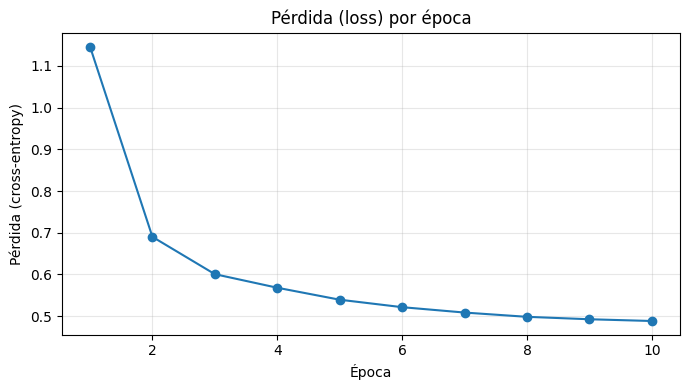


--- MENÚ PRINCIPAL ---
Red convolucional · clasificación original (10 clases) · 784 → 526 → 268 → 10
Parámetros: 556,836 · épocas acumuladas: 10 · adam (lr=0.001), batch=644, dropout=0.8
1. Entrenar
2. Probar
3. Guardar red
4. Cambiar optimizaciones de entrenamiento
5. Crear o cargar otra red
0. Salir
¡Hasta luego!


In [5]:
# menu goes here
def ask(message, default=None, cast=str, valid=None):
    """Ask for a value; Enter keeps the default. Repeats until the value is valid."""
    suffix = f" [{default}]" if default is not None else ""
    while True:
        text = input(f"{message}{suffix}: ").strip()
        if text == "" and default is not None:
            return default
        try:
            value = cast(text)
        except ValueError:
            print("Valor no válido, intente otra vez.")
            continue
        if valid is None or valid(value):
            return value
        print("Valor fuera de rango, intente otra vez.")


def ask_yes_no(message, default=False):
    answer = ask(f"{message} (s/n)", "s" if default else "n", str.lower, lambda v: v in ("s", "n"))
    return answer == "s"


def ask_choice(message, options, default):
    """options: dict {key typed by the user: value}."""
    keys = "/".join(options)
    key = ask(f"{message} ({keys})", default, str.lower, lambda v: v in options)
    return options[key]


def ask_training_options(opts, structural):
    """Ask for optimizations. structural=True also asks dropout and batch norm (only when creating)."""
    opts = dict(opts)
    opts["optimizer"] = ask_choice("Optimizador: 1 = Adam, 2 = SGD con momentum",
                                   {"1": "adam", "2": "sgd"}, "1" if opts["optimizer"] == "adam" else "2")
    opts["learning_rate"] = ask("Learning rate", opts["learning_rate"], float, lambda v: v > 0)
    opts["batch_size"] = ask("Tamaño del batch", opts["batch_size"], int, lambda v: v > 0)
    if structural:
        opts["dropout"] = ask("Dropout (0 = desactivado, máx. 0.9)", opts["dropout"], float,
                              lambda v: 0 <= v <= 0.9)
        opts["batch_norm"] = ask_yes_no("¿Usar batch normalization?", opts["batch_norm"])
    opts["weight_decay"] = ask("Weight decay (0 = desactivado)", opts["weight_decay"], float,
                               lambda v: v >= 0)
    opts["early_stopping"] = ask_yes_no("¿Usar early stopping?", opts["early_stopping"])
    if opts["early_stopping"]:
        opts["patience"] = ask("Paciencia (épocas sin mejorar)", opts["patience"], int, lambda v: v > 0)
    return opts


def create_network_menu():
    print("\n--- Crear red nueva ---")
    classification = ask_choice("Clasificación: 1 = original (10 clases), 2 = simplificada (4 clases)",
                                {"1": "original", "2": "simplified"}, "1")
    hidden_layers = ask("Número de capas ocultas", 2, int, lambda v: v >= 1)
    architecture = ask_choice("Tipo: 1 = rectangular, 2 = convolucional",
                              {"1": "rectangular", "2": "convolutional"}, "1")
    neurons = None
    if architecture == "rectangular":
        neurons = ask("Neuronas por capa oculta", 512, int, lambda v: v >= 1)
    opts = dict(DEFAULT_OPTIONS)
    if ask_yes_no("¿Configurar optimizaciones?", False):
        opts = ask_training_options(opts, structural=True)
    return create_network(classification, architecture, hidden_layers, neurons, **opts)


def load_network_menu():
    path = ask("Ruta del archivo .pth")
    try:
        network = load_network(path)
    except (OSError, RuntimeError, KeyError) as error:
        print("No se pudo cargar la red:", error)
        return None
    return network


def main_menu():
    network = None
    while True:
        if network is None:
            print("\n=== RED NEURONAL · FASHION MNIST ===")
            print("1. Crear red nueva")
            print("2. Cargar red desde archivo")
            print("0. Salir")
            option = input("Elija una opción: ").strip()
            if option == "1":
                network = create_network_menu()
            elif option == "2":
                network = load_network_menu()
            elif option == "0":
                print("¡Hasta luego!")
                return
            else:
                print("Opción no válida, intente otra vez.")
            continue

        print("\n--- MENÚ PRINCIPAL ---")
        describe_network(network)
        print("1. Entrenar")
        print("2. Probar")
        print("3. Guardar red")
        print("4. Cambiar optimizaciones de entrenamiento")
        print("5. Crear o cargar otra red")
        print("0. Salir")
        option = input("Elija una opción: ").strip()
        hp = network["hyperparameters"]

        if option == "1":
            epochs = ask("Número de épocas", 10, int, lambda v: v >= 1)
            train_data, _ = load_datasets(hp["classification"])
            first_epoch = hp["epochs"] + 1
            train_losses, validation_losses = train_network(network, train_data, epochs)
            plot_losses(train_losses, validation_losses, first_epoch)
        elif option == "2":
            _, test_data = load_datasets(hp["classification"])
            show_results(network, evaluate_network(network, test_data))
        elif option == "3":
            path = ask("Nombre del archivo", default_filename(network))
            try:
                save_network(network, path)
            except OSError as error:
                print("No se pudo guardar la red:", error)
        elif option == "4":
            hp["optimizations"] = ask_training_options(hp["optimizations"], structural=False)
        elif option == "5":
            network = None
        elif option == "0":
            print("¡Hasta luego!")
            return
        else:
            print("Opción no válida, intente otra vez.")
            
            
main_menu()
